In [1]:
import pandas as pd
import numpy as np
import koreanize_matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%config InlineBackend.figure_format = 'retina'
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv('movie_finished_toFDA_수익성+드랍률+검색량변화.csv', encoding='cp949')

In [3]:
df

In [4]:
# # min-max 정규화
# df['개봉일_좌석수)'] = (df['개봉일_좌석수'] - df['개봉일_좌석수'].min()) / (df['개봉일_좌석수'].max() - df['개봉일_좌석수'].min())
# df['규모_수익성'] = (df['규모_수익성'] - df['규모_수익성'].min()) / (df['규모_수익성'].max() - df['규모_수익성'].min())

# # k-means 모델 생성
# kmeans = KMeans(n_clusters=4, random_state=123)

# # 모델 학습
# kmeans.fit(df)

# # 군집 결과
# df['cluster'] = kmeans.labels_

# # 군집 시각화
# plt.figure(figsize=(10, 6))
# sns.scatterplot(data=df, x='개봉일_좌석수', y='규모_수익성', hue='cluster', palette='Set2', s=100)
# plt.title('k-means 군집화 결과')
# plt.show()

In [5]:
# 영화별 개봉일의 좌석수
df_규모_수익성 = pd.DataFrame()
df_규모_수익성['movie_title'] = df['movie_title'].unique()
df_규모_수익성

In [6]:
# 15번째마다 행 남기기
df_규모_수익성 = pd.merge(df[::15][['좌석수', 'movie_title']], df_규모_수익성, on='movie_title', how='left').copy()
df_규모_수익성

In [7]:
df_규모_수익성 = pd.merge(df[['movie_title','누적_매출액']], df_규모_수익성, on='movie_title', how='left').copy()
df_규모_수익성

In [8]:
# 영화별로 묶기
df_규모_수익성 = df_규모_수익성.groupby(['movie_title']).mean()

# 수익성
df_규모_수익성['수익성'] = df_규모_수익성['누적_매출액'] / df_규모_수익성['좌석수']
df_규모_수익성

In [9]:
df_규모_수익성.rename(columns={'좌석수':'규모(좌석수)'}, inplace=True)
df_규모_수익성.drop('누적_매출액', axis=1, inplace=True)
df_규모_수익성

/var/folders/7j/q4f5lfds7cn41ftj48m1vkn40000gn/T/ipykernel_49513/3122100250.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_규모_수익성['규모(좌석수)'])


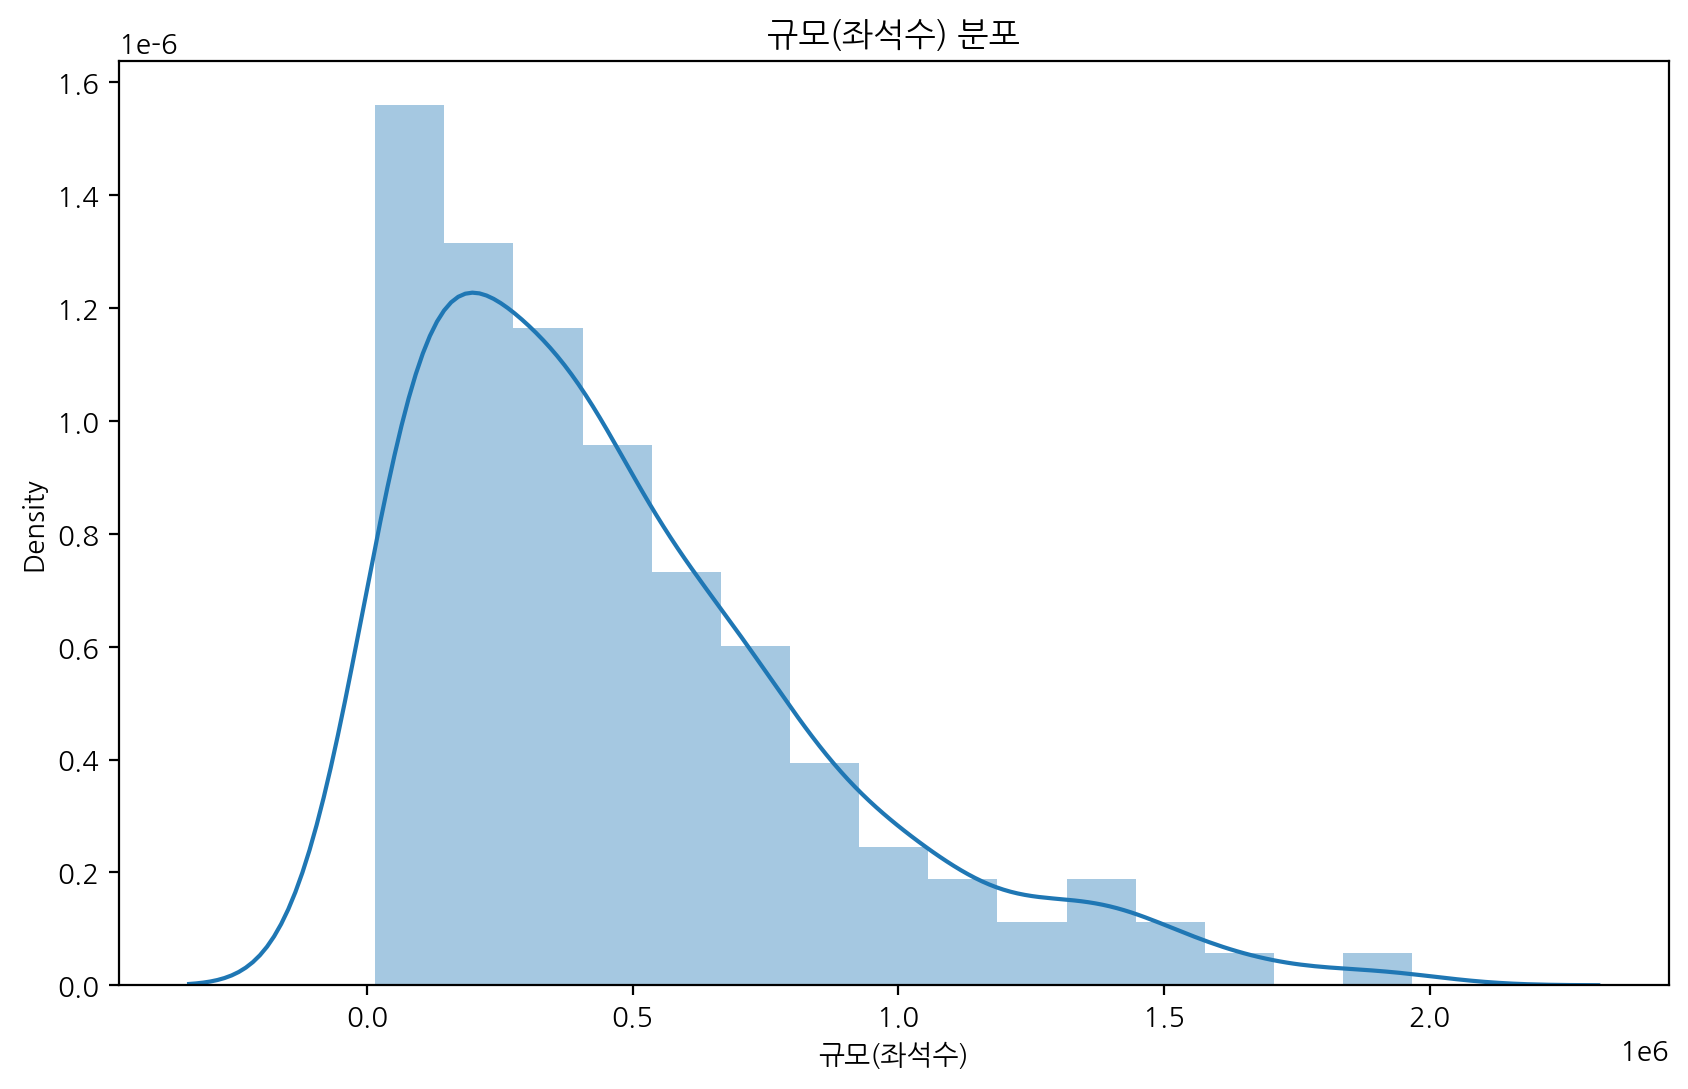

In [10]:
# 규모의 분포
plt.figure(figsize=(10, 6))
sns.distplot(df_규모_수익성['규모(좌석수)'])
plt.title('규모(좌석수) 분포')
plt.show()

/var/folders/7j/q4f5lfds7cn41ftj48m1vkn40000gn/T/ipykernel_49513/1484571289.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_규모_수익성['수익성'])


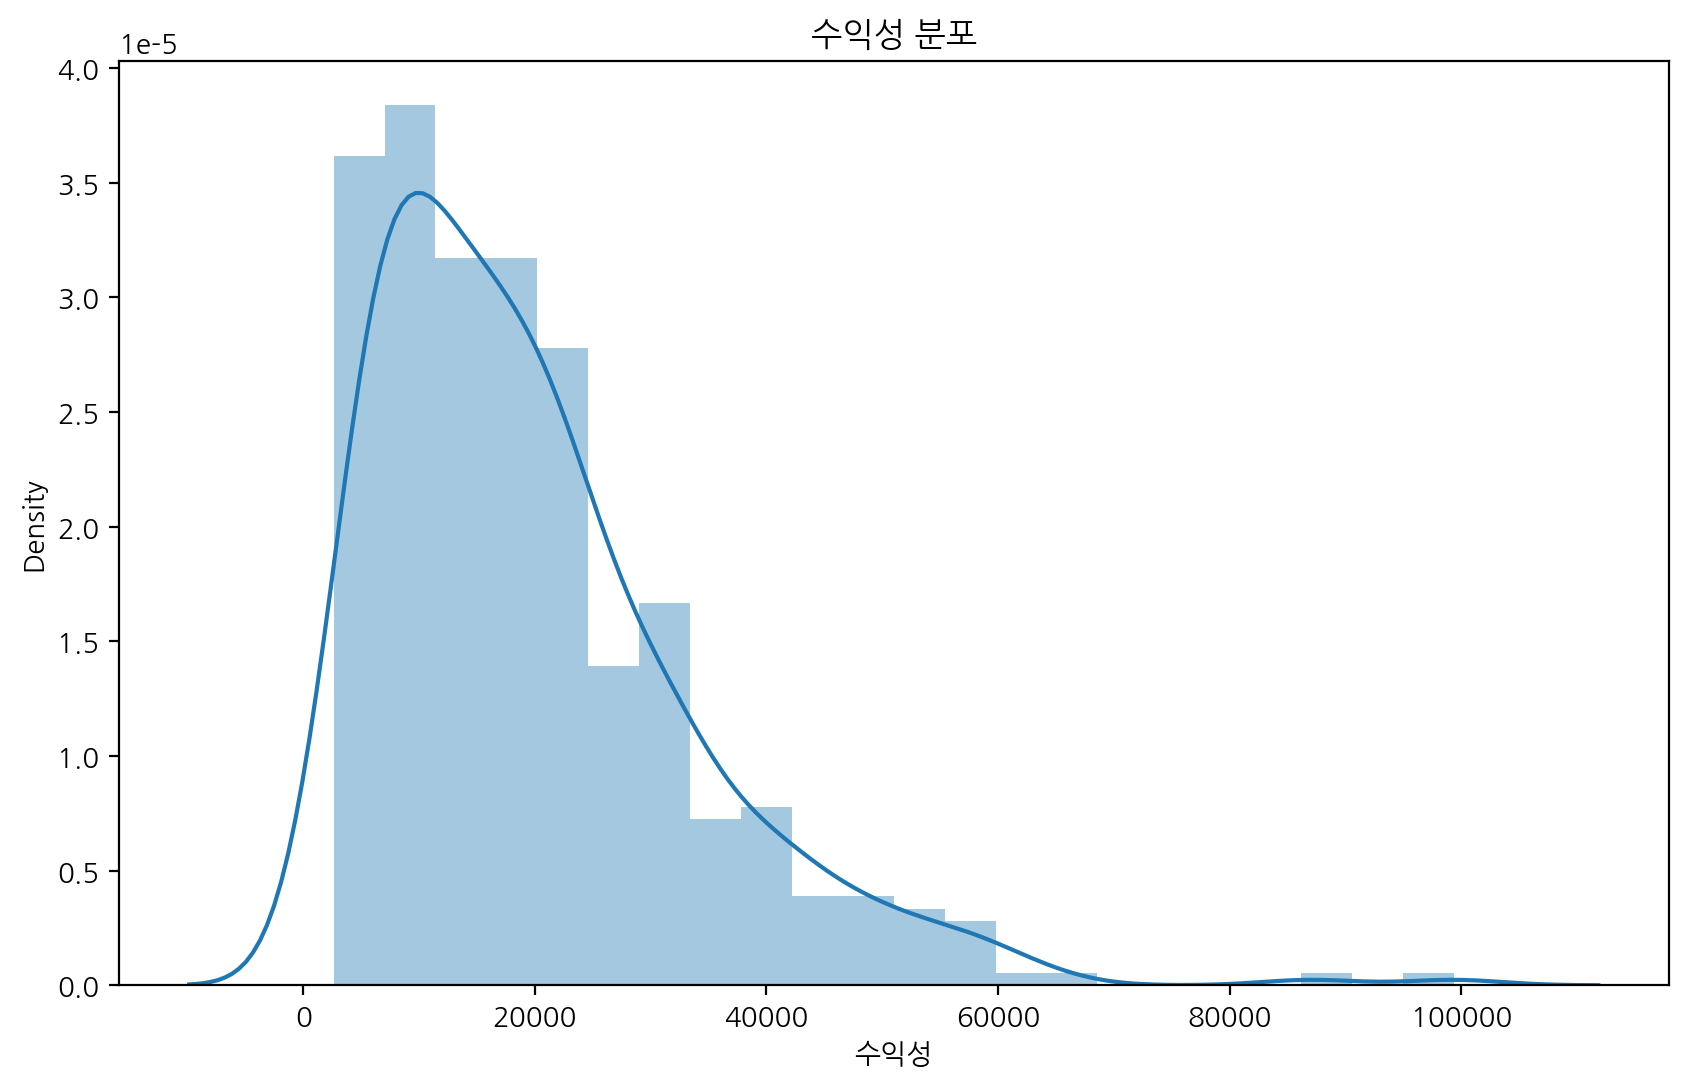

In [11]:
# 수익성의 분포
plt.figure(figsize=(10, 6))
sns.distplot(df_규모_수익성['수익성'])
plt.title('수익성 분포')
plt.show()

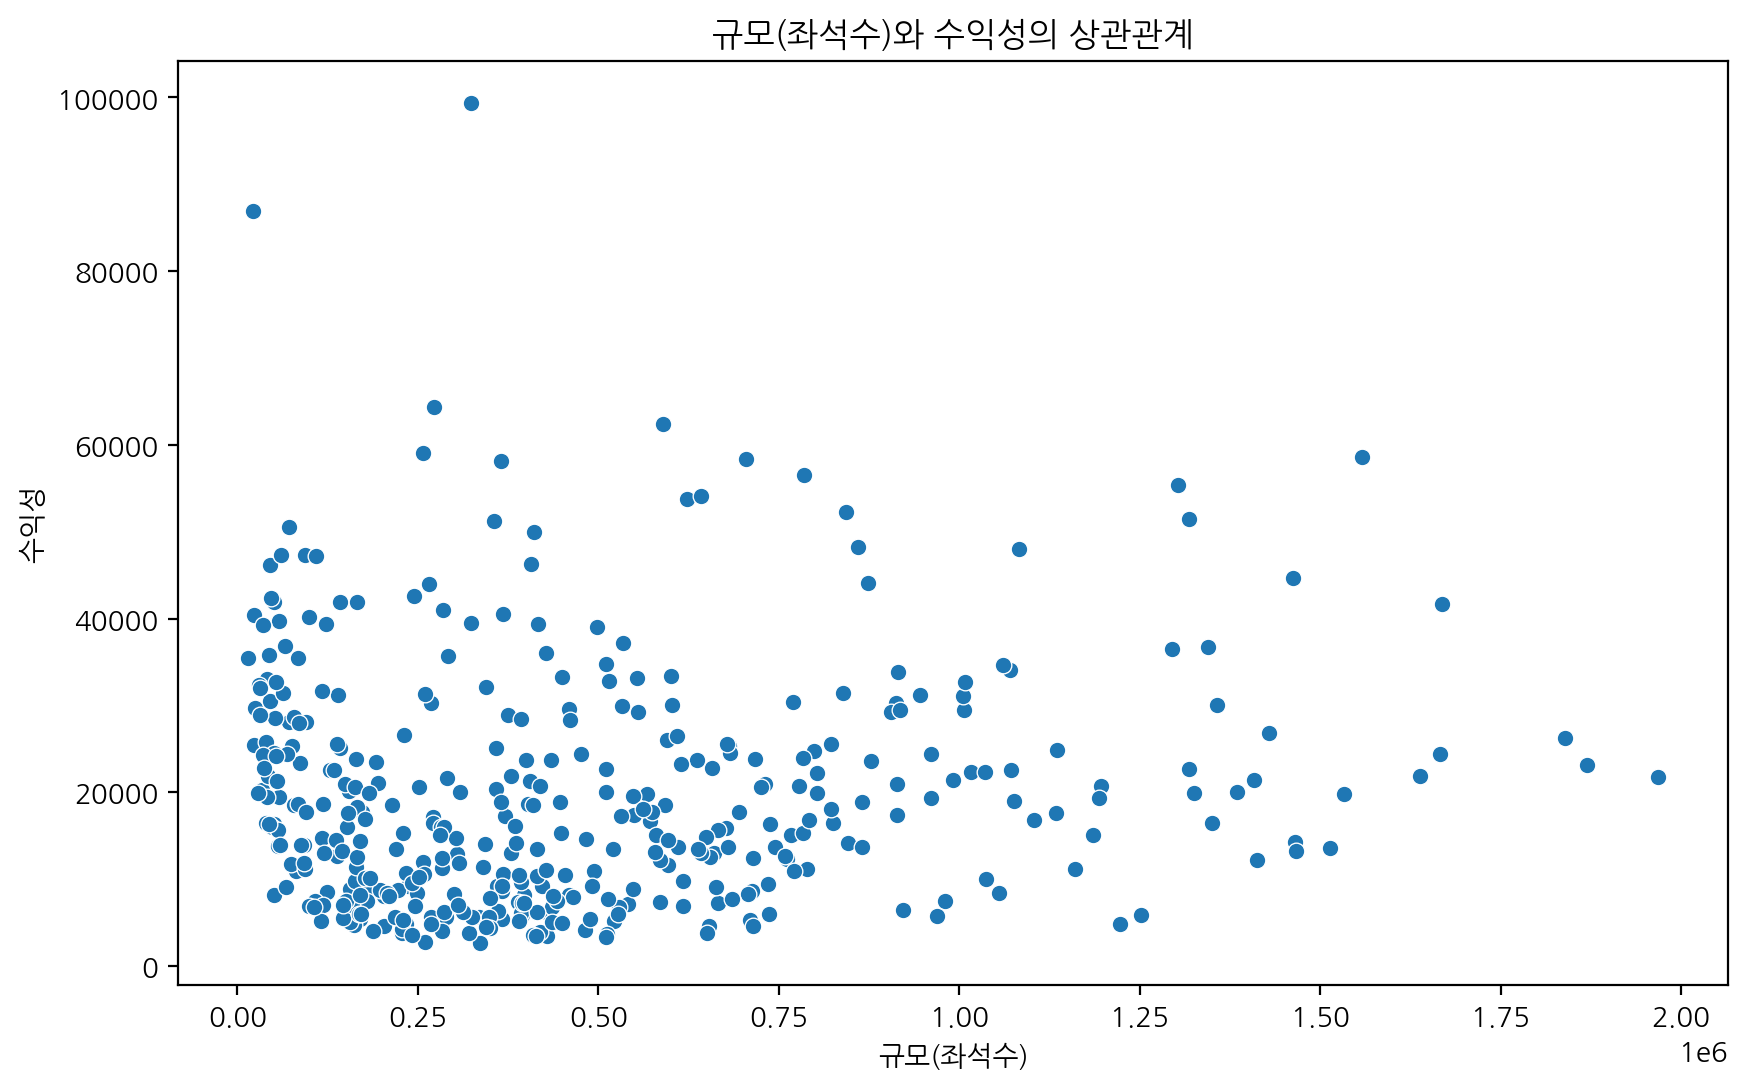

In [12]:
# 규모(좌석수)와 수익성의 상관관계
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_규모_수익성, x='규모(좌석수)', y='수익성')
plt.title('규모(좌석수)와 수익성의 상관관계')
plt.show()

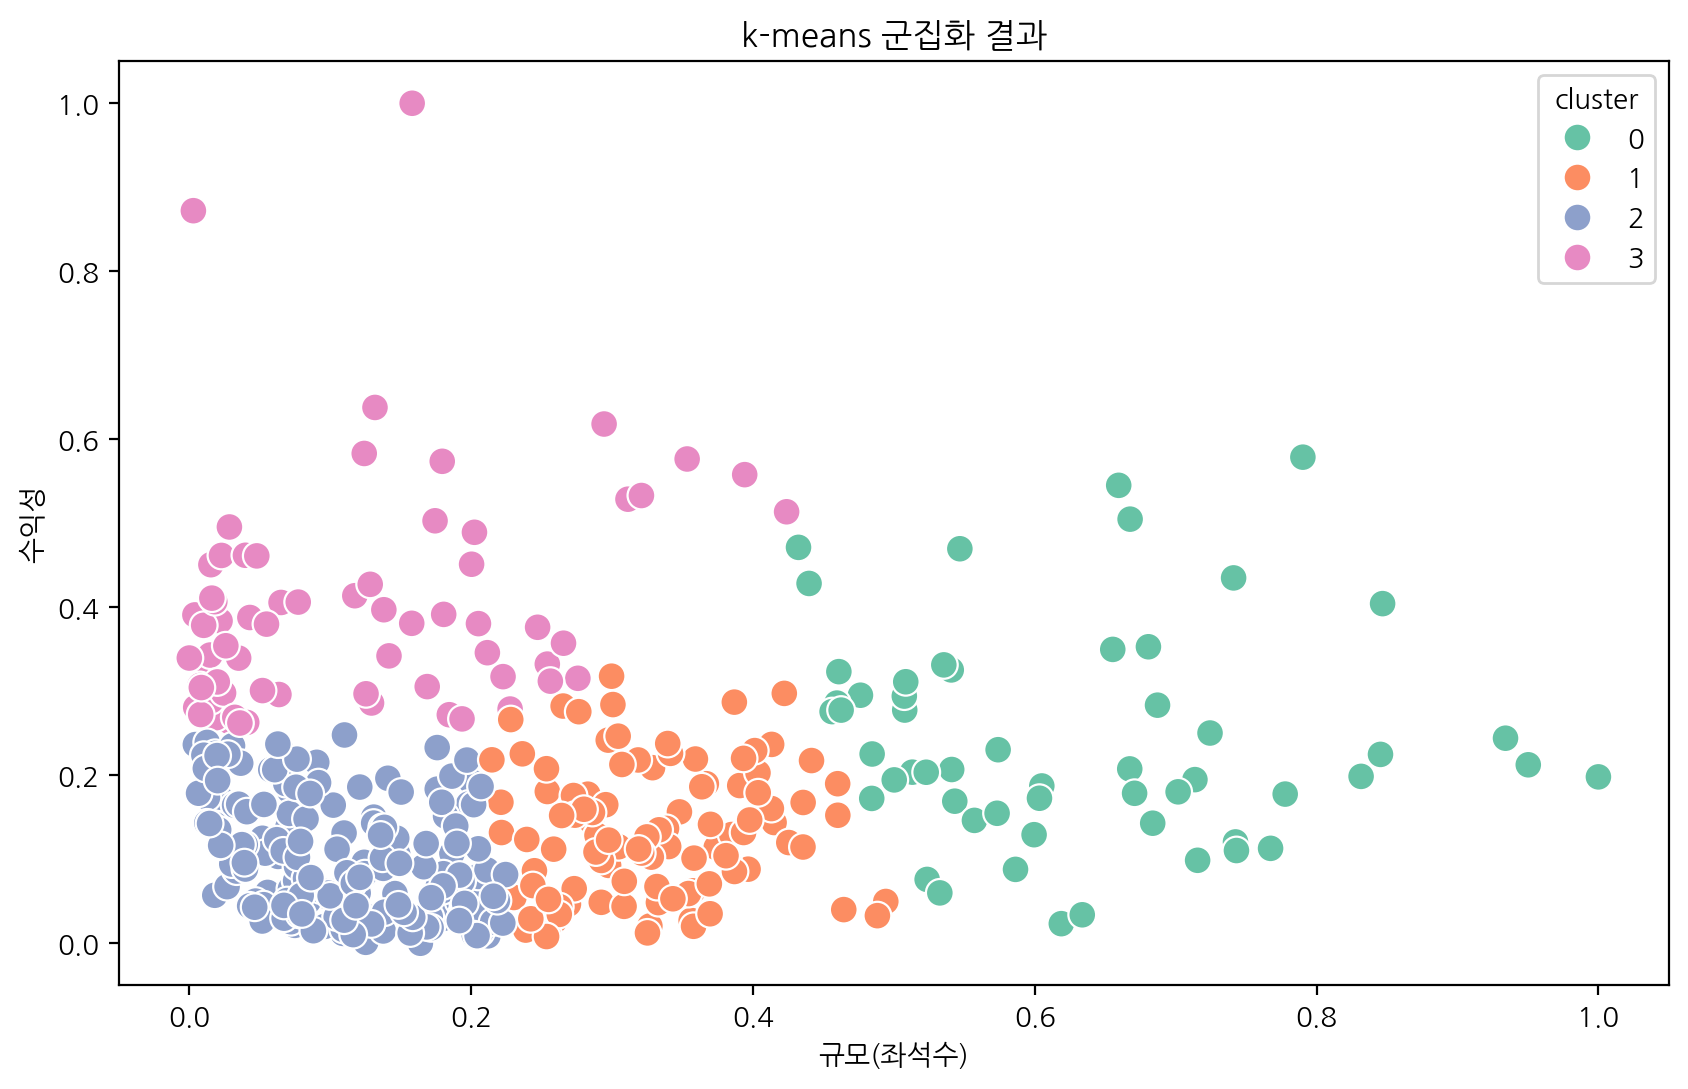

In [13]:
# min-max 정규화
df_규모_수익성['규모(좌석수)'] = (df_규모_수익성['규모(좌석수)'] - df_규모_수익성['규모(좌석수)'].min()) / (df_규모_수익성['규모(좌석수)'].max() - df_규모_수익성['규모(좌석수)'].min())
df_규모_수익성['수익성'] = (df_규모_수익성['수익성'] - df_규모_수익성['수익성'].min()) / (df_규모_수익성['수익성'].max() - df_규모_수익성['수익성'].min())

# k-means 모델 생성
kmeans = KMeans(n_clusters=4, random_state=123)

# 모델 학습
kmeans.fit(df_규모_수익성)

# 군집 결과
df_규모_수익성['cluster'] = kmeans.labels_

# 군집 시각화
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_규모_수익성, x='규모(좌석수)', y='수익성', hue='cluster', palette='Set2', s=100)
plt.title('k-means 군집화 결과')
plt.show()

In [33]:
# 군집별 통계량
df_규모_수익성.groupby('cluster').mean()

In [ ]:
# 군집 개수
df_규모_수익성['cluster'].value_counts()

cluster
2    184
1    103
3     67
0     55
Name: count, dtype: int64

In [15]:
df_규모_수익성_0 = df_규모_수익성[df_규모_수익성['cluster'] == 0]
df_규모_수익성_1 = df_규모_수익성[df_규모_수익성['cluster'] == 1]
df_규모_수익성_2 = df_규모_수익성[df_규모_수익성['cluster'] == 2]
df_규모_수익성_3 = df_규모_수익성[df_규모_수익성['cluster'] == 3]

In [16]:
df

In [34]:
df_규모_수익성_0

In [35]:
df_규모_수익성_1

In [36]:
df_규모_수익성_2

In [37]:
df_규모_수익성_3

In [17]:
df = df.merge(df_규모_수익성_0[['cluster']], on='movie_title', how='left')

In [18]:
df

In [19]:
# df_규모_수익성_1의 cluster 값 병합
df = df.merge(df_규모_수익성_1[['cluster']], on='movie_title', how='left', suffixes=('', '_new'))
df['cluster'] = df['cluster'].fillna(df['cluster_new'])  # NaN 값을 대체
df.drop(columns=['cluster_new'], inplace=True)  # 임시 열 제거

# df_규모_수익성_2의 cluster 값 병합
df = df.merge(df_규모_수익성_2[['cluster']], on='movie_title', how='left', suffixes=('', '_new'))
df['cluster'] = df['cluster'].fillna(df['cluster_new'])  # NaN 값을 대체
df.drop(columns=['cluster_new'], inplace=True)  # 임시 열 제거

# df_규모_수익성_3의 cluster 값 병합
df = df.merge(df_규모_수익성_3[['cluster']], on='movie_title', how='left', suffixes=('', '_new'))
df['cluster'] = df['cluster'].fillna(df['cluster_new'])  # NaN 값을 대체
df.drop(columns=['cluster_new'], inplace=True)  # 임시 열 제거


In [20]:
df

In [21]:
df['cluster'].isnull().sum()

0

In [22]:
# 클러스터별 데이터 개수 확인
cluster_counts = df['cluster'].value_counts()
print("클러스터별 데이터 개수:")
print(cluster_counts)

클러스터별 데이터 개수:
cluster
2.0    2760
1.0    1545
3.0    1005
0.0     825
Name: count, dtype: int64


In [24]:
# 상관 분석할 열 지정
columns_to_analyze = ['누적_매출액', '규모_수익성', 'NTZ_score_total', 'drop_ratio', 'week1_change', 'week2_change']

# 클러스터별 상관 분석
correlation_by_cluster = {}
for cluster in df['cluster'].unique():
    # 특정 클러스터 데이터 필터링
    cluster_data = df[df['cluster'] == cluster]
    
    # NaN 제거
    cluster_data_cleaned = cluster_data[columns_to_analyze].dropna()
    
    if not cluster_data_cleaned.empty:
        # 상관 분석 수행
        correlation_df = cluster_data_cleaned.corr()
        correlation_by_cluster[cluster] = correlation_df
        print(f"Cluster {cluster} 상관 분석 결과:")
        print(correlation_df)
        print("\n")
    else:
        print(f"Cluster {cluster}에는 NaN을 제외한 유효한 데이터가 없습니다.\n")

Cluster 2.0 상관 분석 결과:
                   누적_매출액    규모_수익성  NTZ_score_total  drop_ratio  \
누적_매출액           1.000000  0.428408         0.037498   -0.093558   
규모_수익성           0.428408  1.000000         0.344134   -0.610039   
NTZ_score_total  0.037498  0.344134         1.000000   -0.433990   
drop_ratio      -0.093558 -0.610039        -0.433990    1.000000   
week1_change    -0.125510  0.228145         0.247999   -0.361128   
week2_change    -0.076708 -0.107117        -0.130179    0.096941   

                 week1_change  week2_change  
누적_매출액              -0.125510     -0.076708  
규모_수익성               0.228145     -0.107117  
NTZ_score_total      0.247999     -0.130179  
drop_ratio          -0.361128      0.096941  
week1_change         1.000000     -0.066888  
week2_change        -0.066888      1.000000  


Cluster 0.0 상관 분석 결과:
                   누적_매출액    규모_수익성  NTZ_score_total  drop_ratio  \
누적_매출액           1.000000  0.884369         0.372488   -0.436043   
규모_수익성           0.

In [25]:
# Cluster 0 상관 분석
cluster_0_data = df[df['cluster'] == 0]
cluster_0_cleaned = cluster_0_data[columns_to_analyze].dropna()
if not cluster_0_cleaned.empty:
    correlation_0 = cluster_0_cleaned.corr()
    print("Cluster 0 상관 분석 결과:")
    print(correlation_0)
else:
    print("Cluster 0에는 NaN을 제외한 유효한 데이터가 없습니다.")
print("\n" + "="*50 + "\n")

Cluster 0 상관 분석 결과:
                   누적_매출액    규모_수익성  NTZ_score_total  drop_ratio  \
누적_매출액           1.000000  0.884369         0.372488   -0.436043   
규모_수익성           0.884369  1.000000         0.491737   -0.621945   
NTZ_score_total  0.372488  0.491737         1.000000   -0.535646   
drop_ratio      -0.436043 -0.621945        -0.535646    1.000000   
week1_change     0.197499  0.242986         0.266521   -0.293053   
week2_change     0.144362  0.145240         0.240150    0.049301   

                 week1_change  week2_change  
누적_매출액               0.197499      0.144362  
규모_수익성               0.242986      0.145240  
NTZ_score_total      0.266521      0.240150  
drop_ratio          -0.293053      0.049301  
week1_change         1.000000     -0.377293  
week2_change        -0.377293      1.000000  




In [26]:
# Cluster 1 상관 분석
cluster_1_data = df[df['cluster'] == 1]
cluster_1_cleaned = cluster_1_data[columns_to_analyze].dropna()
if not cluster_1_cleaned.empty:
    correlation_1 = cluster_1_cleaned.corr()
    print("Cluster 1 상관 분석 결과:")
    print(correlation_1)
else:
    print("Cluster 1에는 NaN을 제외한 유효한 데이터가 없습니다.")
print("\n" + "="*50 + "\n")

Cluster 1 상관 분석 결과:
                   누적_매출액    규모_수익성  NTZ_score_total  drop_ratio  \
누적_매출액           1.000000  0.914160         0.474454   -0.576434   
규모_수익성           0.914160  1.000000         0.504514   -0.631231   
NTZ_score_total  0.474454  0.504514         1.000000   -0.522117   
drop_ratio      -0.576434 -0.631231        -0.522117    1.000000   
week1_change     0.260049  0.215050         0.219372   -0.376184   
week2_change    -0.084418 -0.059271         0.009116    0.003237   

                 week1_change  week2_change  
누적_매출액               0.260049     -0.084418  
규모_수익성               0.215050     -0.059271  
NTZ_score_total      0.219372      0.009116  
drop_ratio          -0.376184      0.003237  
week1_change         1.000000     -0.221221  
week2_change        -0.221221      1.000000  




In [27]:
# Cluster 2 상관 분석
cluster_2_data = df[df['cluster'] == 2]
cluster_2_cleaned = cluster_2_data[columns_to_analyze].dropna()
if not cluster_2_cleaned.empty:
    correlation_2 = cluster_2_cleaned.corr()
    print("Cluster 2 상관 분석 결과:")
    print(correlation_2)
else:
    print("Cluster 2에는 NaN을 제외한 유효한 데이터가 없습니다.")
print("\n" + "="*50 + "\n")

Cluster 2 상관 분석 결과:
                   누적_매출액    규모_수익성  NTZ_score_total  drop_ratio  \
누적_매출액           1.000000  0.428408         0.037498   -0.093558   
규모_수익성           0.428408  1.000000         0.344134   -0.610039   
NTZ_score_total  0.037498  0.344134         1.000000   -0.433990   
drop_ratio      -0.093558 -0.610039        -0.433990    1.000000   
week1_change    -0.125510  0.228145         0.247999   -0.361128   
week2_change    -0.076708 -0.107117        -0.130179    0.096941   

                 week1_change  week2_change  
누적_매출액              -0.125510     -0.076708  
규모_수익성               0.228145     -0.107117  
NTZ_score_total      0.247999     -0.130179  
drop_ratio          -0.361128      0.096941  
week1_change         1.000000     -0.066888  
week2_change        -0.066888      1.000000  




In [28]:
# Cluster 3 상관 분석
cluster_3_data = df[df['cluster'] == 3]
cluster_3_cleaned = cluster_3_data[columns_to_analyze].dropna()
if not cluster_3_cleaned.empty:
    correlation_3 = cluster_3_cleaned.corr()
    print("Cluster 3 상관 분석 결과:")
    print(correlation_3)
else:
    print("Cluster 3에는 NaN을 제외한 유효한 데이터가 없습니다.")
print("\n" + "="*50 + "\n")

Cluster 3 상관 분석 결과:
                   누적_매출액    규모_수익성  NTZ_score_total  drop_ratio  \
누적_매출액           1.000000  0.523810        -0.203860   -0.173151   
규모_수익성           0.523810  1.000000         0.079246   -0.390977   
NTZ_score_total -0.203860  0.079246         1.000000   -0.206908   
drop_ratio      -0.173151 -0.390977        -0.206908    1.000000   
week1_change    -0.175038  0.264981         0.076322   -0.442444   
week2_change     0.007080  0.064316         0.028064   -0.038040   

                 week1_change  week2_change  
누적_매출액              -0.175038      0.007080  
규모_수익성               0.264981      0.064316  
NTZ_score_total      0.076322      0.028064  
drop_ratio          -0.442444     -0.038040  
week1_change         1.000000      0.016913  
week2_change         0.016913      1.000000  




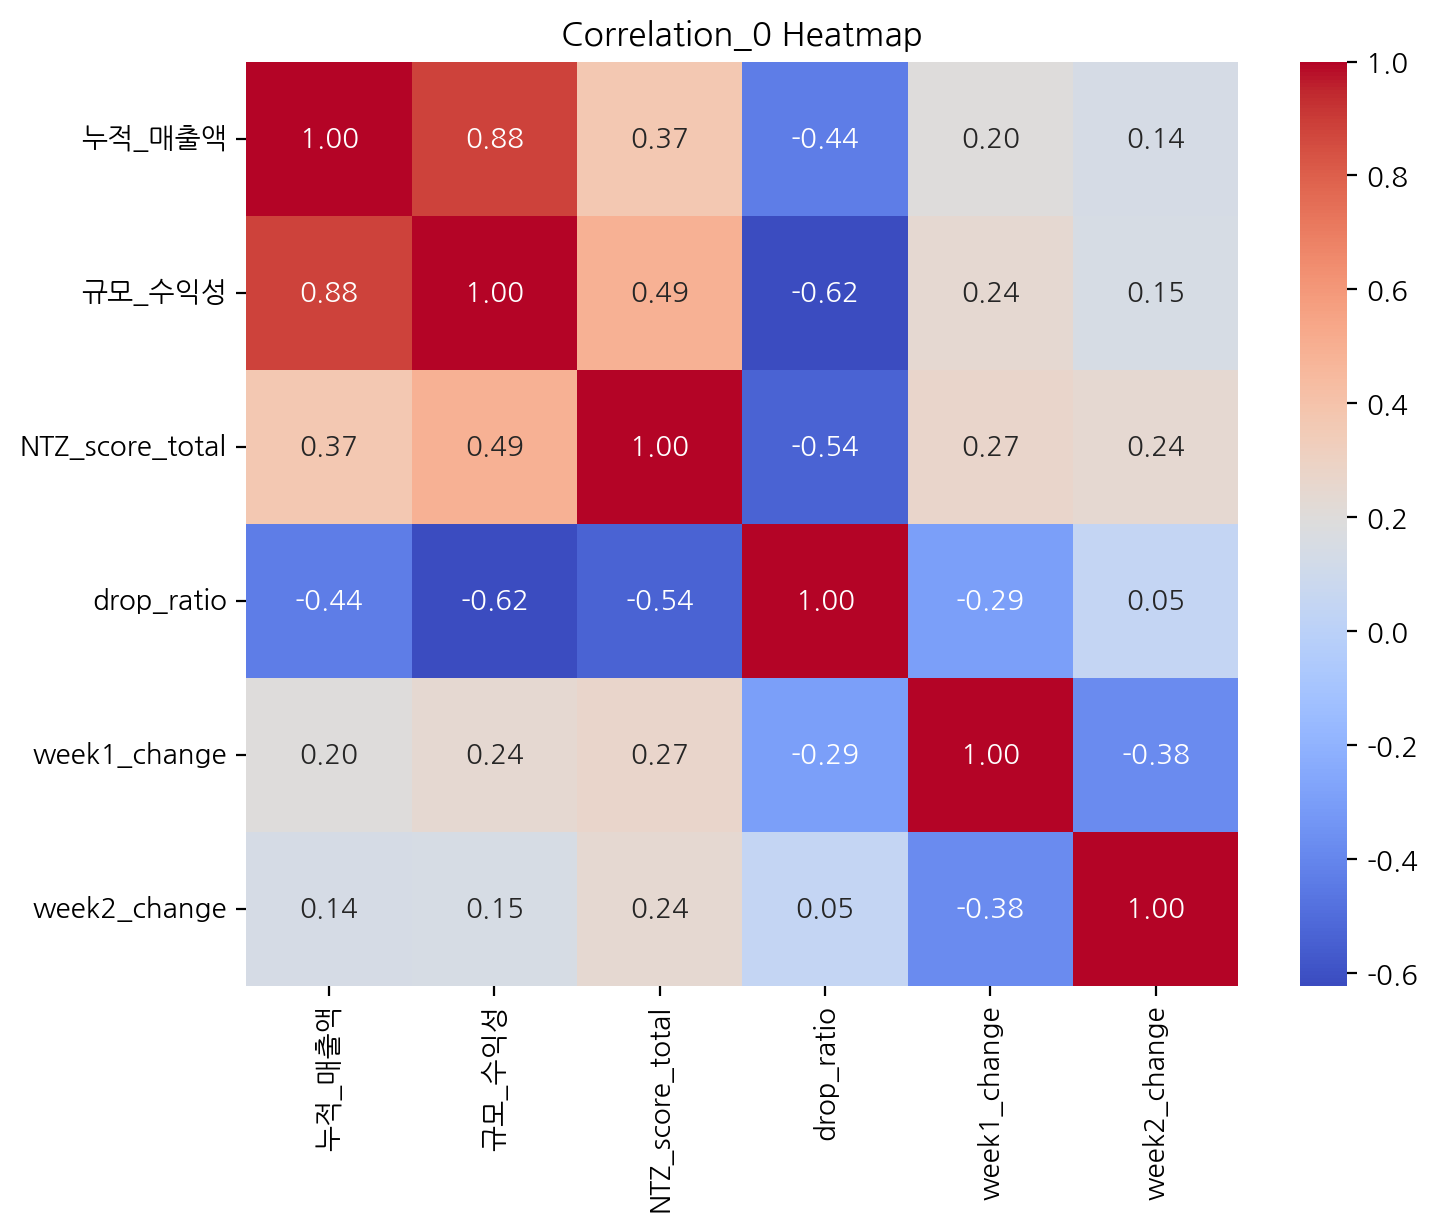

In [29]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_0, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation_0 Heatmap")
plt.show()

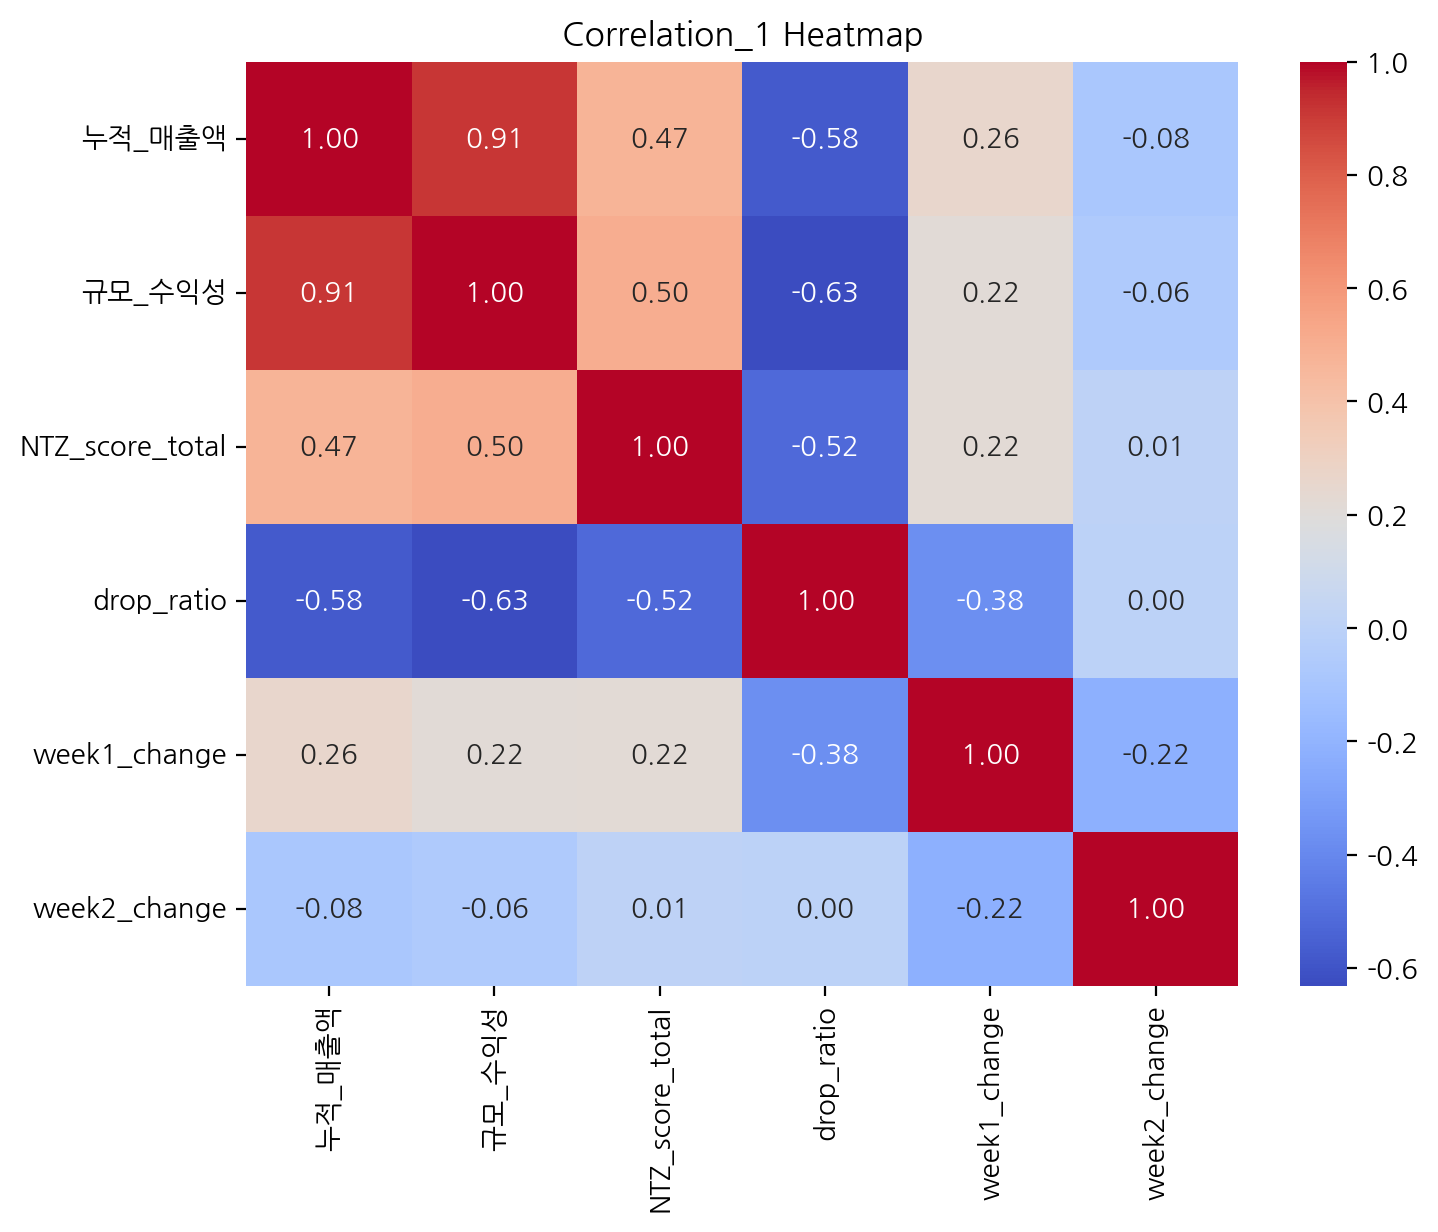

In [30]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_1, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation_1 Heatmap")
plt.show()

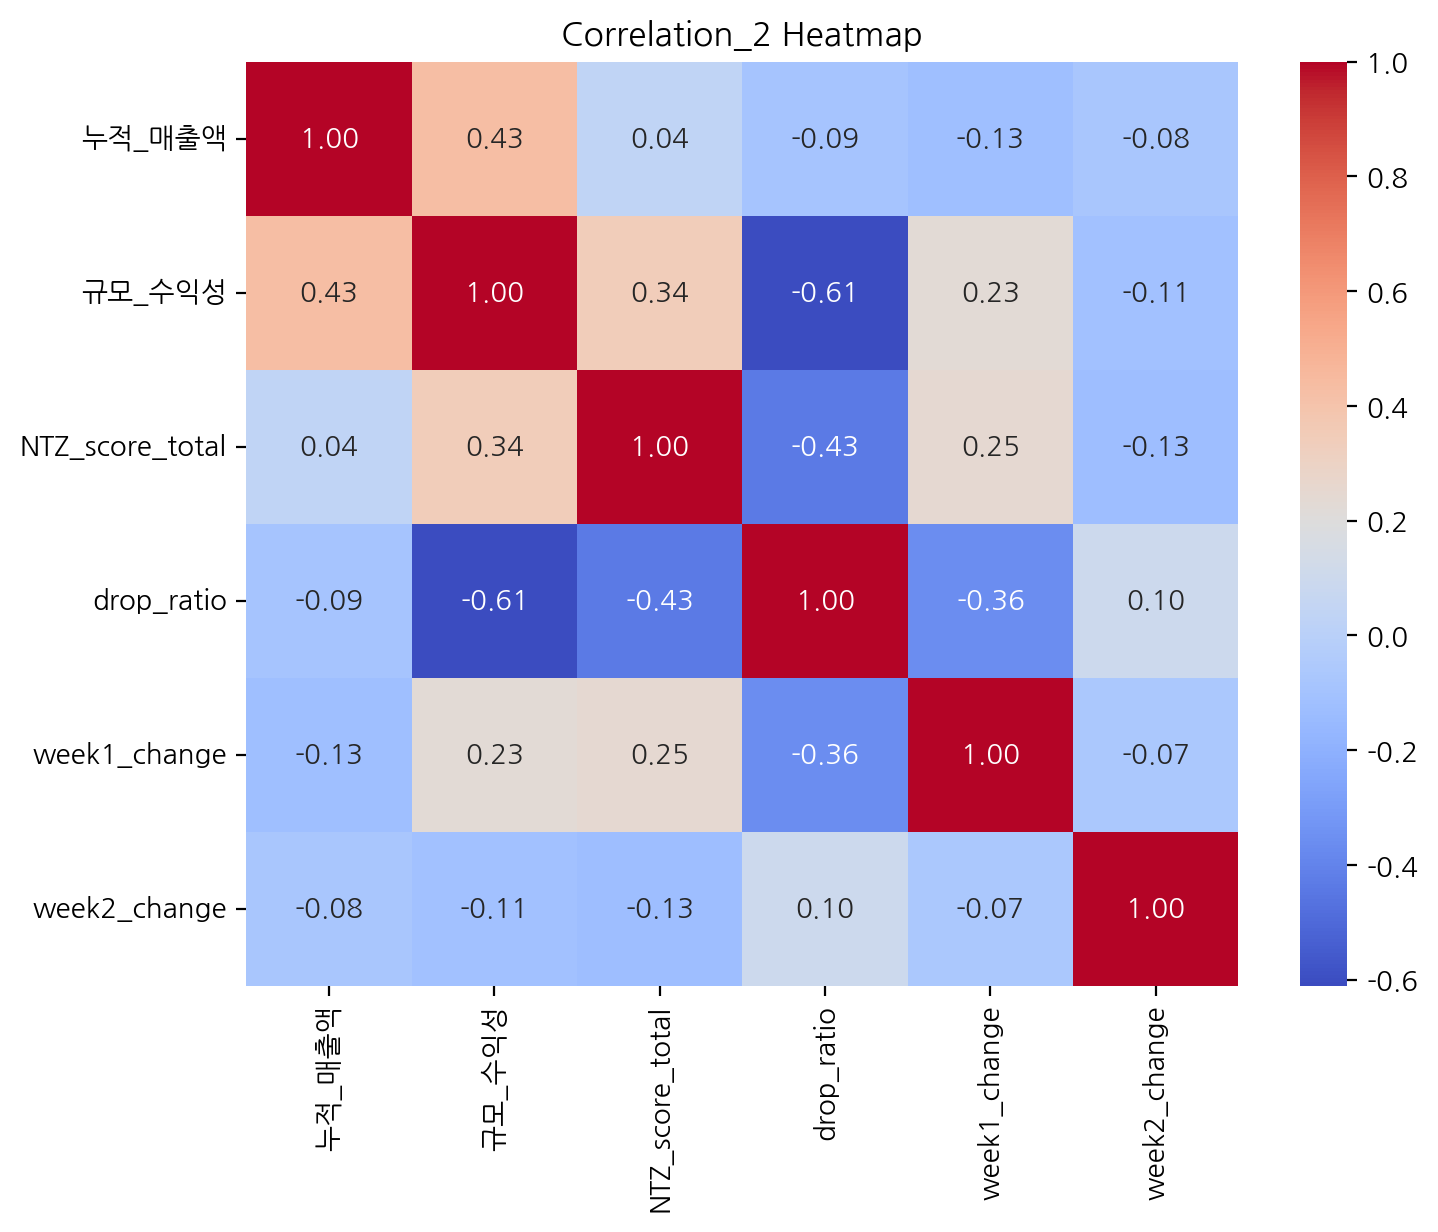

In [31]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_2, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation_2 Heatmap")
plt.show()

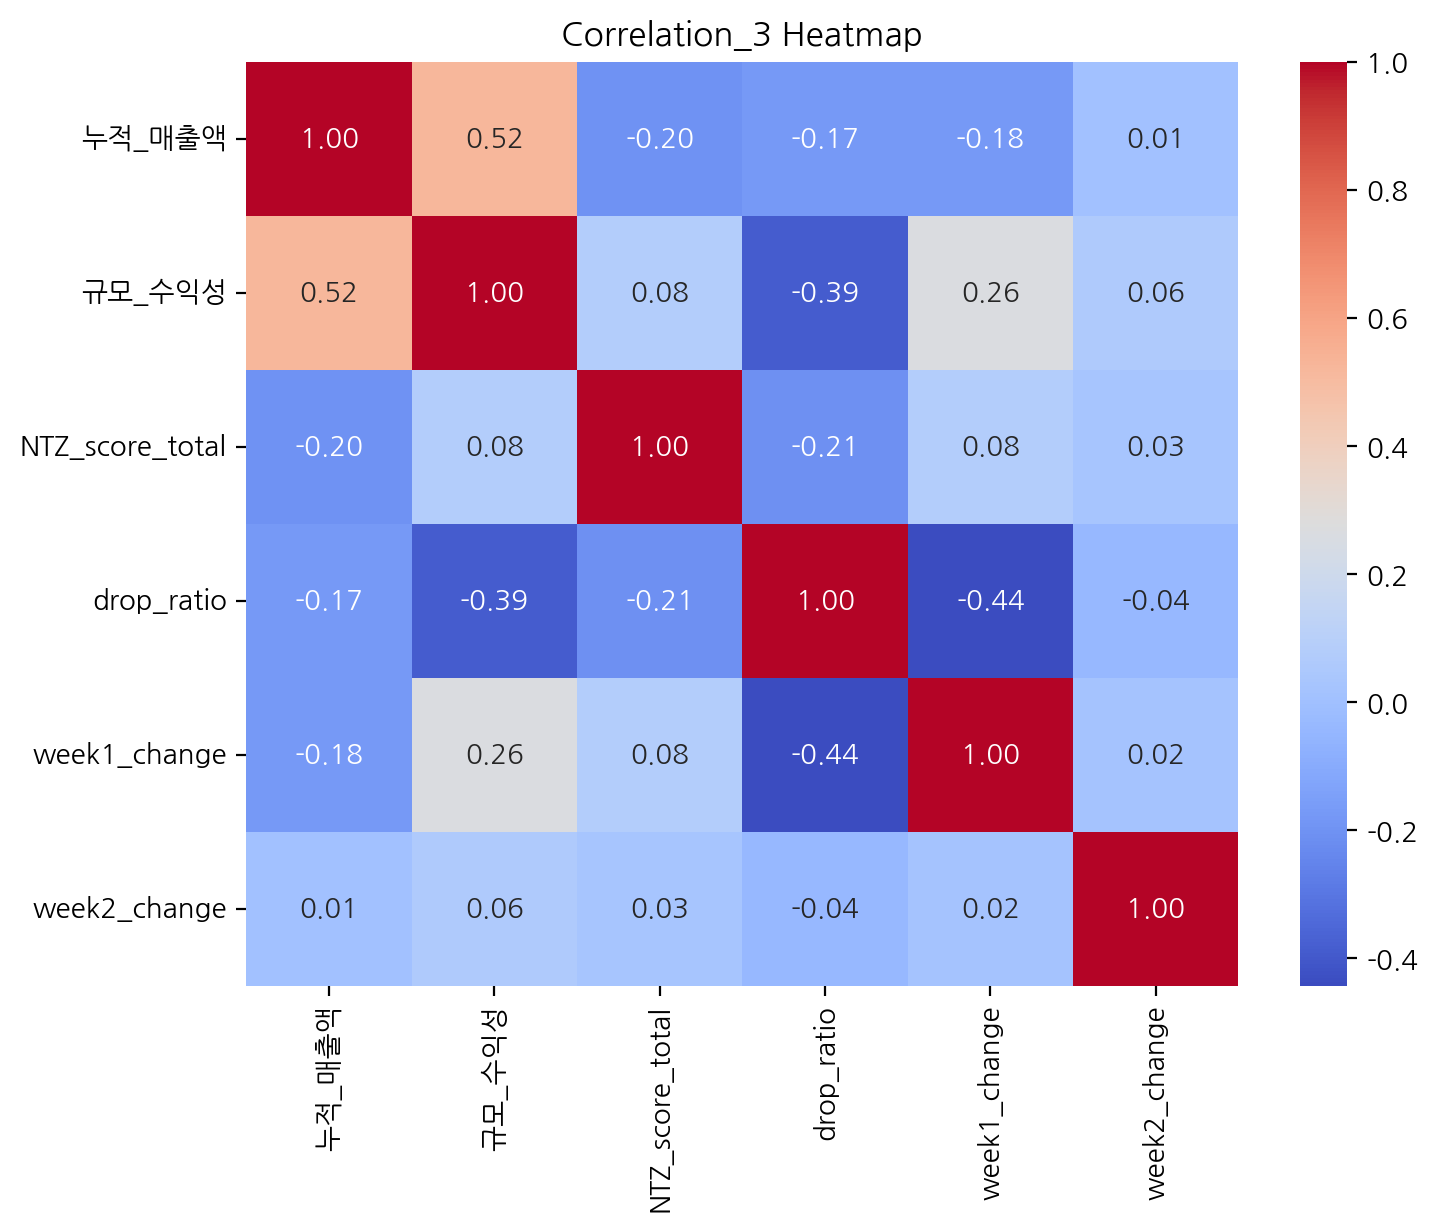

In [32]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_3, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation_3 Heatmap")
plt.show()

In [38]:
df